# Disciplyn: Trader Behaviour Classification (Model Training)

**Goal:** detect 20 behavioural tags (10 negative, 10 positive) from a trader's trade book, order book, market context
and onboarding questionnaire, so the RAG + LLM coach can give tailored advice.

**20 tags → 14 binary models.** Six tag pairs are mutually exclusive opposites, so one model each:

| Model | Negative (1) | Positive (0) |
|---|---|---|
| stop_loss | Ignoring Stop-Losses | Stop-Loss Adherence |
| frequency | Overtrading | Controlled Trading Frequency |
| discipline | Lack of Discipline | Disciplined Trading |
| profit_exit | Greed | Profit Booking |
| entry_timing | FOMO | Patience |
| leverage | Overleveraging | Risk Management |

The other 8 have their own models: Revenge Trading, Panic Selling, Loss Aversion, Confirmation Bias, Emotional Stability,
Consistent Position Sizing, Learning from Losses, Strategic Consistency.

**Notebook outline:** 1. Dataset → 2. EDA → 3. Feature engineering → 4. Train/test split → 5. Algorithm comparison (5-fold CV)
→ 6. Hyper-parameter tuning + threshold tuning → 7. Test evaluation (ROC, confusion matrices) → 8. Explainability
→ 9. Effect of data size → 10. Cold start (no questionnaire) → 11. Inference on sample traders.

In [1]:
import time, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", font_scale=0.9)
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
from features import MODELS
import training_pipeline as tp
print("models defined:", len(MODELS))

models defined: 14


## 1. Dataset

No public dataset labels retail trades with behaviour tags, so we **simulated 10,000 Indian retail traders over
60 trading days** (`generate_dataset.py`). Each simulated trader has hidden behavioural traits, and two latent
factors, *impulsivity* and *fear*, correlate the traits as they would in real people. The traits drive every
decision: trade frequency, re-entering after a loss, chasing moves, moving stop-losses, holding losers, leverage,
switching strategies, journaling.

The labels come from the hidden traits. The models only see what a **broker API (trade book + order book)**,
the **Market Data API** and the **questionnaire** would provide, so the test scores measure real detection ability.

In [2]:
trades = pd.read_csv("data/trades.csv")
traders = pd.read_csv("data/traders.csv")
quest = pd.read_csv("data/questionnaire.csv")
labels = pd.read_csv("data/labels.csv")
print(f"trades        : {trades.shape[0]:>10,} rows x {trades.shape[1]} columns")
print(f"traders       : {traders.shape[0]:>10,}")
print(f"questionnaire : {quest.shape[0]:>10,} answers from {quest.trader_id.nunique():,} traders ({quest.trader_id.nunique()/len(traders):.0%})")
print(f"labels        : {labels.shape[0]:>10,} traders x {labels.shape[1]-1} tags")
print(f"symbols       : {trades.symbol.nunique()} NSE instruments, date range {trades.trade_date.min()} -> {trades.trade_date.max()}")
trades.head(5)

trades        :  1,944,823 rows x 40 columns
traders       :     10,000
questionnaire :     69,620 answers from 6,962 traders (70%)
labels        :     10,000 traders x 20 tags
symbols       : 17 NSE instruments, date range 2026-07-01 -> 2026-09-20


,trader_id,trade_id,trade_date,entry_time,exit_time,symbol,side,qty,entry_price,exit_price,pnl,capital_at_entry,leverage,strategy,in_trading_plan,stop_loss_set,stop_loss_price,target_set,target_price,sl_modified_count,sl_widened,sl_hit,sl_honored,target_hit_but_held,averaged_down,exit_reason,mfe_r,mae_r,r_multiple,holding_minutes,pre_entry_return_15m_pct,volume_zscore_entry,rsi_14_entry,macd_hist_entry,market_sentiment_entry,india_vix,market_move_during_hold_pct,volume_zscore_exit,post_exit_return_30m_pct,journal_note
0,TR00000,TR00000-0000,2026-07-01,2026-07-01T10:06,2026-07-01T11:31,TCS,LONG,237,4126.90,3997.63,-30636.17,647000.00,1.512,Mean_Reversion,1,1,4078.63,1,4199.66,2,1,1,0.0,0,0,manual,0.108,1.518,-2.678,85.7,0.172,0.789,38.01,-0.987,0.016,12.46,-0.729,0.446,-0.128,1
1,TR00000,TR00000-0001,2026-07-02,2026-07-02T09:46,2026-07-02T11:37,BANKNIFTY_FUT,SHORT,12,52759.68,52838.27,-943.13,616363.83,1.027,Mean_Reversion,1,1,53350.68,1,51461.64,0,0,0,NaN,1,0,manual_late,2.440,0.119,-0.133,111.4,0.428,-0.296,52.73,-0.185,0.711,10.60,-0.212,-0.040,-0.032,0
2,TR00000,TR00000-0002,2026-07-02,2026-07-02T10:25,2026-07-02T11:34,BANKNIFTY_FUT,SHORT,18,51173.99,50943.13,4155.45,615420.70,1.497,Mean_Reversion,1,1,51890.65,1,49633.27,0,0,0,NaN,1,0,manual_late,3.167,0.115,0.322,69.9,0.417,0.514,50.65,0.330,-0.897,10.60,0.110,-0.051,0.544,0
3,TR00000,TR00000-0003,2026-07-02,2026-07-02T11:51,2026-07-02T12:13,LT,SHORT,277,3512.20,3547.75,-9847.59,619576.16,1.570,Mean_Reversion,0,1,3546.09,1,3433.37,0,0,1,1.0,0,0,stop_loss,0.284,1.508,-1.049,22.7,1.657,0.673,47.09,0.328,0.033,10.60,-0.518,-0.766,-0.670,1
4,TR00000,TR00000-0004,2026-07-02,2026-07-02T11:56,2026-07-02T12:24,LT,SHORT,394,3618.64,3566.80,20423.29,609728.57,2.338,Mean_Reversion,1,0,NaN,0,NaN,0,0,0,NaN,0,0,manual,2.833,0.055,1.476,28.5,0.180,-0.289,60.01,-0.175,0.679,10.60,-0.205,-0.931,0.443,1


In [3]:
groups = {
 "Trade book": ["trader_id","trade_id","trade_date","entry_time","exit_time","symbol","side","qty","entry_price","exit_price","pnl","capital_at_entry","leverage","strategy","in_trading_plan","exit_reason","holding_minutes","r_multiple"],
 "Order book": ["stop_loss_set","stop_loss_price","target_set","target_price","sl_modified_count","sl_widened","sl_hit","sl_honored","averaged_down"],
 "Price path": ["mfe_r","mae_r","target_hit_but_held"],
 "Market Data API": ["pre_entry_return_15m_pct","volume_zscore_entry","rsi_14_entry","macd_hist_entry","market_sentiment_entry","india_vix","market_move_during_hold_pct","volume_zscore_exit","post_exit_return_30m_pct"],
 "Journal": ["journal_note"]}
pd.DataFrame([{"source": k, "n_columns": len(v), "columns": ", ".join(v)} for k, v in groups.items()])

,source,n_columns,columns
0,Trade book,18,"trader_id, trade_id, trade_date, entry_time, e..."
1,Order book,9,"stop_loss_set, stop_loss_price, target_set, ta..."
2,Price path,3,"mfe_r, mae_r, target_hit_but_held"
3,Market Data API,9,"pre_entry_return_15m_pct, volume_zscore_entry,..."
4,Journal,1,journal_note


In [4]:
quest[["set_no","question_no","construct","reverse_scored","question","answer"]].drop_duplicates("question").head(10)

,set_no,question_no,construct,reverse_scored,question,answer
0,2,1,impulsivity,0,I often enter a trade quickly so I don't miss ...,2
1,2,2,impulsivity,0,"After a loss, I want to get back into the mark...",3
2,2,3,confirmation_bias,0,"Once I have a view on a stock, I mostly look f...",2
3,2,4,confirmation_bias,1,I actively look for reasons my trade idea coul...,4
4,2,5,emotional,0,"My emotions (fear, frustration, excitement) af...",3
5,2,6,emotional,1,I stay calm when a trade goes against me.,3
6,2,7,discipline,1,"I follow a written trading plan with entry, st...",4
7,2,8,discipline,0,I break my own rules when I feel confident.,1
8,2,9,learning,1,I review my losing trades and note what went w...,2
9,2,10,learning,0,I keep repeating the same mistakes.,4


## 2. Exploratory data analysis

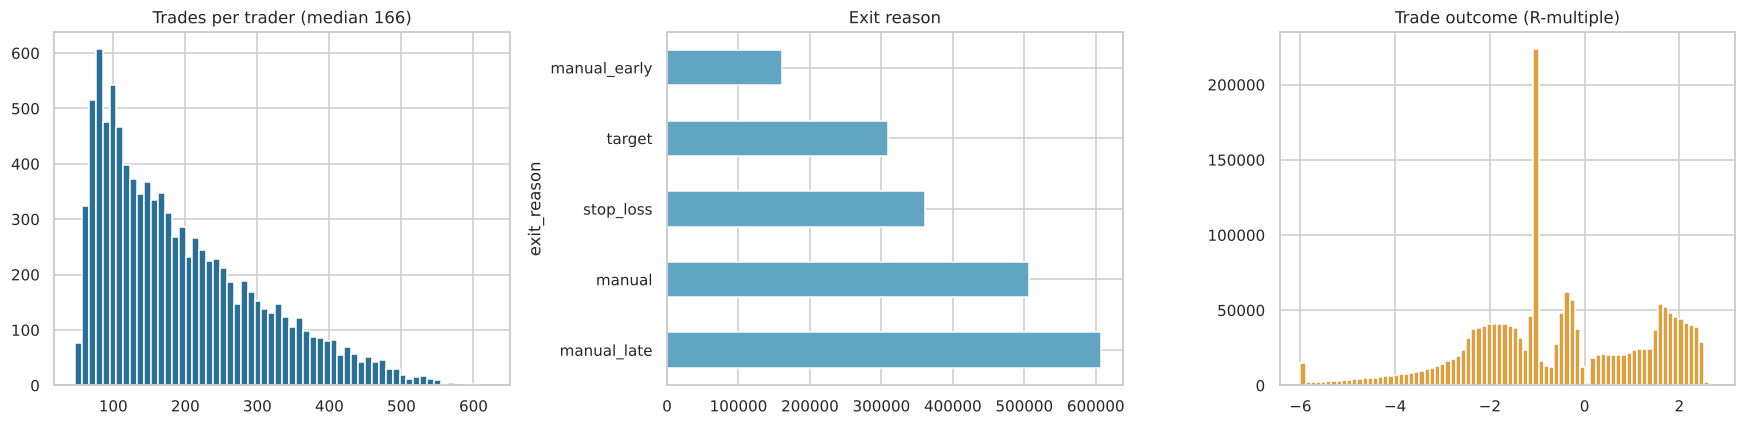

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
tpt = trades.groupby("trader_id").size()
ax[0].hist(tpt, bins=60, color="#2a6f97"); ax[0].set_title(f"Trades per trader (median {int(tpt.median())})")
trades.exit_reason.value_counts().plot.barh(ax=ax[1], color="#61a5c2"); ax[1].set_title("Exit reason")
ax[2].hist(trades.r_multiple.clip(-6, 6), bins=80, color="#e09f3e"); ax[2].set_title("Trade outcome (R-multiple)")
plt.tight_layout()

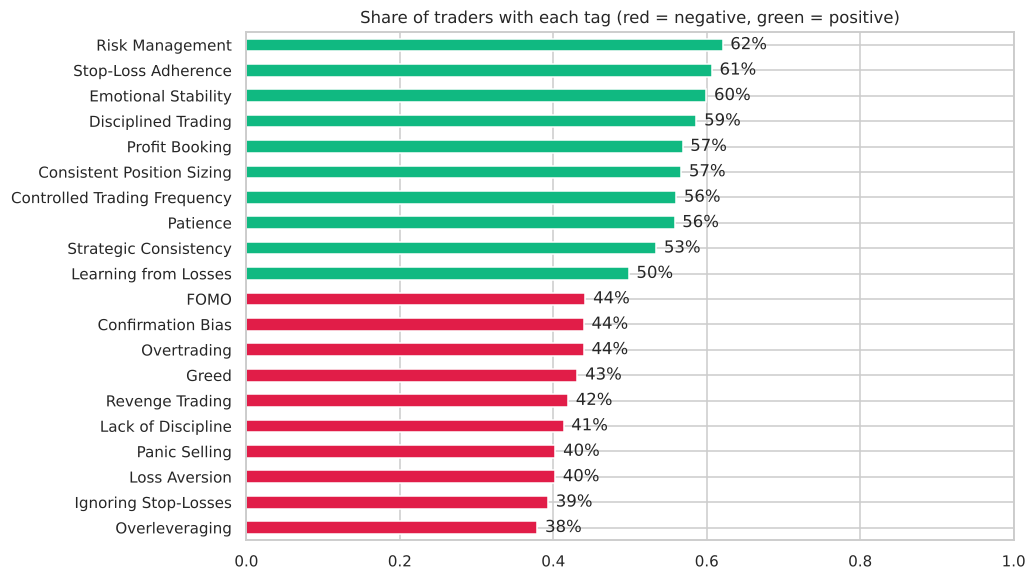

In [6]:
rate = labels.drop(columns="trader_id").mean().sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
neg = {m["negative"] for m in MODELS.values() if m["type"]=="pair"} | {m["tag"] for m in MODELS.values() if m.get("polarity")=="negative"}
rate.plot.barh(ax=ax, color=["#e11d48" if t in neg else "#10b981" for t in rate.index])
ax.set_title("Share of traders with each tag (red = negative, green = positive)"); ax.set_xlim(0, 1)
for i, v in enumerate(rate): ax.text(v + 0.01, i, f"{v:.0%}", va="center")

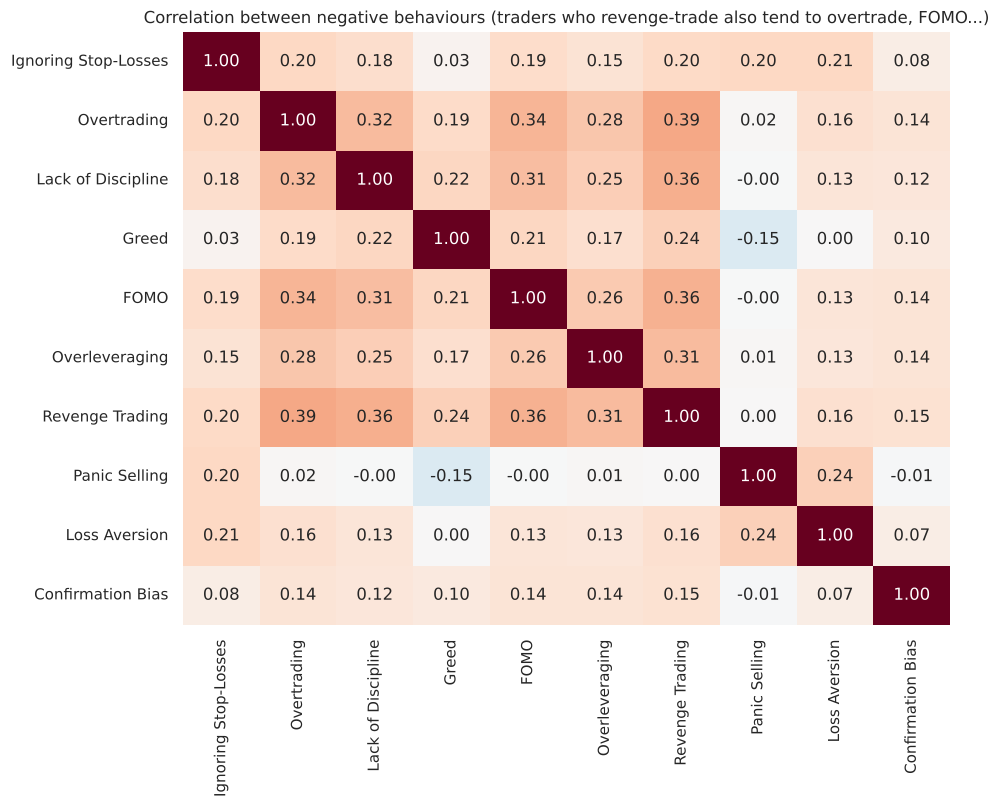

Text(0.5, 1.0, 'Correlation between negative behaviours (traders who revenge-trade also tend to overtrade, FOMO...)')

In [7]:
neg_cols = [t for t in labels.columns if t in neg]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(labels[neg_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, cbar=False)
ax.set_title("Correlation between negative behaviours (traders who revenge-trade also tend to overtrade, FOMO...)")

Each behaviour leaves a measurable footprint in the trades. A few examples, using raw trades joined with their trader's label:

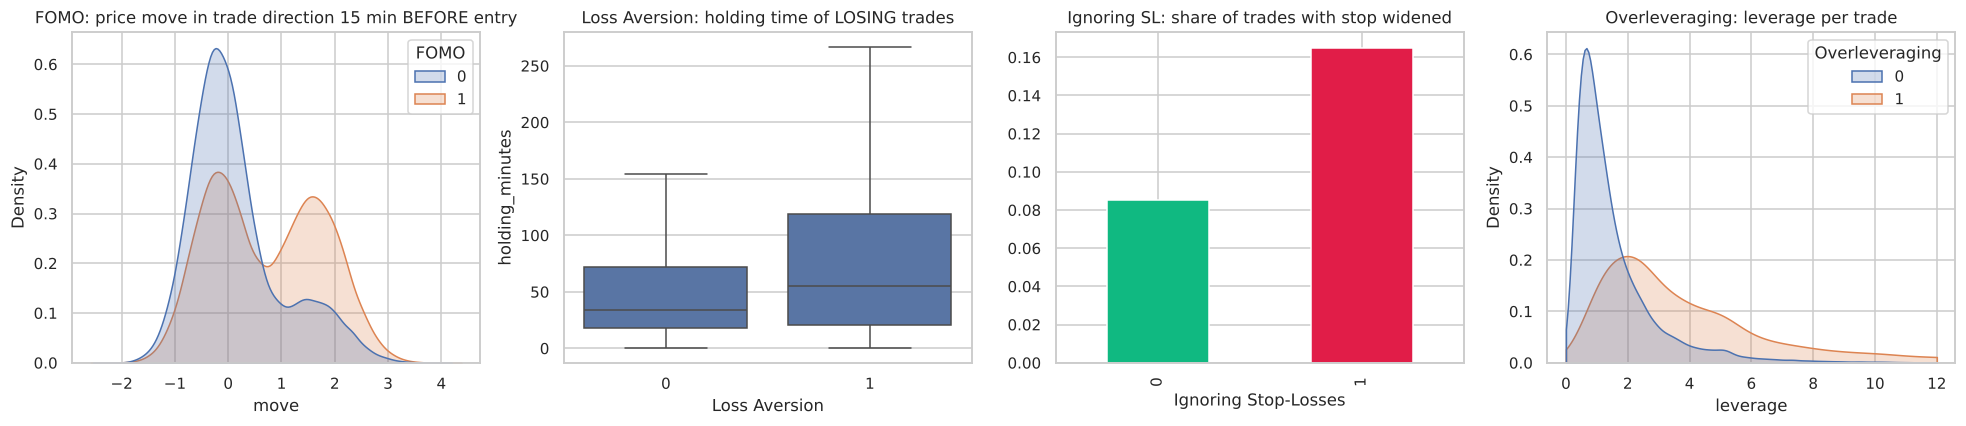

In [8]:
t = trades.merge(labels[["trader_id","FOMO","Loss Aversion","Ignoring Stop-Losses","Overleveraging"]], on="trader_id")
t = t.sample(200_000, random_state=0)
sgn = np.where(t.side=="LONG", 1, -1)
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
sns.kdeplot(data=t.assign(move=t.pre_entry_return_15m_pct*sgn), x="move", hue="FOMO", common_norm=False, ax=ax[0], fill=True)
ax[0].set_title("FOMO: price move in trade direction 15 min BEFORE entry")
sns.boxplot(data=t[t.pnl<0], x="Loss Aversion", y="holding_minutes", ax=ax[1], showfliers=False)
ax[1].set_title("Loss Aversion: holding time of LOSING trades")
t.groupby("Ignoring Stop-Losses").sl_widened.mean().plot.bar(ax=ax[2], color=["#10b981","#e11d48"])
ax[2].set_title("Ignoring SL: share of trades with stop widened")
sns.kdeplot(data=t, x="leverage", hue="Overleveraging", common_norm=False, ax=ax[3], fill=True, clip=(0, 12))
ax[3].set_title("Overleveraging: leverage per trade"); plt.tight_layout()

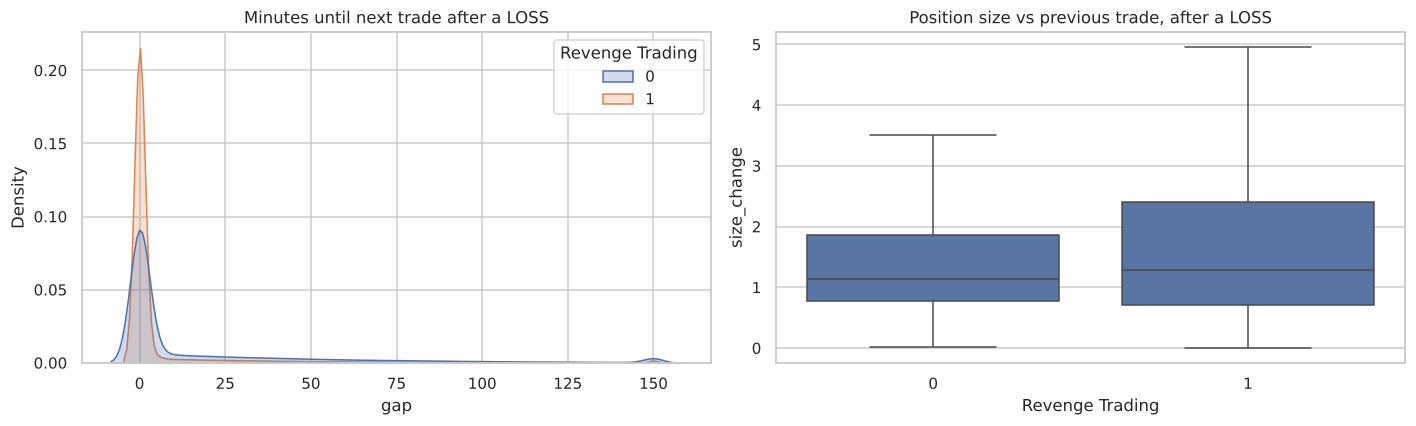

In [9]:
# Revenge trading: what happens right after a losing trade (same day)
s = trades.sort_values(["trader_id","entry_time"]).copy()
s["prev_loss"] = (s.groupby("trader_id").pnl.shift() < 0) & (s.trade_date == s.groupby("trader_id").trade_date.shift())
s["gap"] = (pd.to_datetime(s.entry_time) - pd.to_datetime(s.groupby("trader_id").exit_time.shift())).dt.total_seconds()/60
s["size_change"] = s.leverage / s.groupby("trader_id").leverage.shift()
s = s[s.prev_loss].merge(labels[["trader_id","Revenge Trading"]], on="trader_id")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.kdeplot(data=s, x=s.gap.clip(0, 150), hue="Revenge Trading", common_norm=False, fill=True, ax=ax[0])
ax[0].set_title("Minutes until next trade after a LOSS")
sns.boxplot(data=s, x="Revenge Trading", y=s.size_change.clip(0, 5), showfliers=False, ax=ax[1])
ax[1].set_title("Position size vs previous trade, after a LOSS"); plt.tight_layout()

## 3. Feature engineering

`features.py` turns raw trades into **behavioural features**. One training sample is **one trader-month
(a 20-trading-day window)**, the same unit used in production, where every user is re-scored monthly to track improvement.
Each of the 14 models uses **its own feature subset**, chosen from the evidence for that behaviour.
Missing questionnaire answers (existing users) stay as NaN.

In [10]:
df = tp.load_dataset()
feat_cols = sorted({f for m in MODELS.values() for f in m["features"]})
print(f"training samples (trader-month windows): {len(df):,} from {df.trader_id.nunique():,} traders")
print(f"engineered features: {len(feat_cols)}  | windows with questionnaire: {df.q_impulsivity.notna().mean():.0%}")
pd.DataFrame([{"model": k, "target": tp.target_of(v), "n_features": len(v["features"]), "features": ", ".join(v["features"])}
              for k, v in MODELS.items()])

training samples (trader-month windows): 28,875 from 10,000 traders
engineered features: 66  | windows with questionnaire: 70%


,model,target,n_features,features
0,stop_loss,Ignoring Stop-Losses,7,"sl_set_rate, sl_modified_rate, sl_widened_rate..."
1,frequency,Overtrading,7,"trades_per_day, max_trades_per_day, median_gap..."
2,discipline,Lack of Discipline,7,"sl_set_rate, target_set_rate, off_plan_rate, t..."
3,profit_exit,Greed,6,"target_held_rate, giveback_ratio, win_hold_vs_..."
4,entry_timing,FOMO,6,"chase_entry_rate, avg_pre_entry_move, avg_entr..."
5,leverage,Overleveraging,6,"avg_leverage, max_leverage, p90_leverage, avg_..."
6,revenge,Revenge Trading,6,"gap_after_loss_vs_win, quick_reentry_after_los..."
7,panic,Panic Selling,6,"early_exit_rate, early_exit_in_selloff_rate, p..."
8,loss_aversion,Loss Aversion,6,"loss_hold_vs_win_hold, averaged_down_rate, avg..."
9,confirmation_bias,Confirmation Bias,5,"same_idea_reentry_rate, against_macd_rate, aga..."


In [11]:
df[feat_cols].describe().T[["mean","std","min","50%","max"]].round(3).head(25)

,mean,std,min,50%,max
active_days_ratio,0.972,0.114,0.452,1.000,1.647
against_macd_rate,0.595,0.095,0.077,0.597,1.000
against_sentiment_rate,0.594,0.110,0.000,0.596,1.000
averaged_down_rate,0.111,0.075,0.000,0.103,0.545
avg_entry_volume_z,1.164,0.546,-0.258,1.123,2.825
avg_exit_volume_z,0.659,0.351,-0.754,0.603,3.924
avg_leverage,2.544,2.228,0.124,1.867,31.418
avg_loss_r,-1.650,0.386,-3.338,-1.621,-0.318
avg_pre_entry_move,0.377,0.363,-0.717,0.348,1.485
avg_risk_pct_capital,2.545,2.232,0.126,1.866,31.204


## 4. Train / test split (by trader)

All windows from one trader go to the same side of the split (`GroupShuffleSplit`), so the test set contains
**traders the models have never seen**. Cross-validation uses `GroupKFold` for the same reason.

In [12]:
train, test = tp.split(df, test_size=0.2)
print(f"train: {len(train):,} windows / {train.trader_id.nunique():,} traders")
print(f"test : {len(test):,} windows / {test.trader_id.nunique():,} traders")
print("trader overlap:", len(set(train.trader_id) & set(test.trader_id)))

train: 23,124 windows / 8,000 traders
test : 5,751 windows / 2,000 traders
trader overlap: 0


## 5. Algorithm comparison (5-fold GroupKFold, ROC-AUC)

Each of the 14 tasks is tested with 4 algorithm families. The best one per tag goes forward to tuning.
XGBoost and LightGBM are added automatically if they are installed.

In [13]:
t0 = time.time()
comparison, algo_cols = tp.compare_algorithms(train, folds=5)
print(f"\ncompleted in {(time.time()-t0)/60:.1f} min")
comparison[["model","tag(s)"] + algo_cols + ["best_algorithm"]]

  stop_loss              LogisticRegression     CV ROC-AUC 0.9477 ± 0.0032  (0s)
  stop_loss              RandomForest           CV ROC-AUC 0.9495 ± 0.0021  (7s)
  stop_loss              HistGradientBoosting   CV ROC-AUC 0.9500 ± 0.0026  (4s)
  stop_loss              MLP (Neural Net)       CV ROC-AUC 0.9499 ± 0.0039  (3s)
  frequency              LogisticRegression     CV ROC-AUC 0.9772 ± 0.0007  (0s)
  frequency              RandomForest           CV ROC-AUC 0.9800 ± 0.0010  (5s)
  frequency              HistGradientBoosting   CV ROC-AUC 0.9815 ± 0.0011  (3s)
  frequency              MLP (Neural Net)       CV ROC-AUC 0.9792 ± 0.0008  (3s)
  discipline             LogisticRegression     CV ROC-AUC 0.9826 ± 0.0025  (0s)
  discipline             RandomForest           CV ROC-AUC 0.9825 ± 0.0024  (5s)
  discipline             HistGradientBoosting   CV ROC-AUC 0.9829 ± 0.0021  (3s)
  discipline             MLP (Neural Net)       CV ROC-AUC 0.9833 ± 0.0020  (3s)
  profit_exit            Log

,model,tag(s),LogisticRegression,RandomForest,HistGradientBoosting,MLP (Neural Net),best_algorithm
0,stop_loss,Ignoring Stop-Losses / Stop-Loss Adherence,0.9477,0.9495,0.9500,0.9499,HistGradientBoosting
1,frequency,Overtrading / Controlled Trading Frequency,0.9772,0.9800,0.9815,0.9792,HistGradientBoosting
2,discipline,Lack of Discipline / Disciplined Trading,0.9826,0.9825,0.9829,0.9833,MLP (Neural Net)
3,profit_exit,Greed / Profit Booking,0.9521,0.9525,0.9525,0.9520,RandomForest
4,entry_timing,FOMO / Patience,0.9680,0.9671,0.9671,0.9673,LogisticRegression
5,leverage,Overleveraging / Risk Management,0.9093,0.9063,0.9091,0.9103,MLP (Neural Net)
6,revenge,Revenge Trading,0.9080,0.9145,0.9162,0.9153,HistGradientBoosting
7,panic,Panic Selling,0.9105,0.9078,0.9107,0.9109,MLP (Neural Net)
8,loss_aversion,Loss Aversion,0.9064,0.9087,0.9090,0.9119,MLP (Neural Net)
9,confirmation_bias,Confirmation Bias,0.9634,0.9629,0.9636,0.9632,HistGradientBoosting


best_algorithm
MLP (Neural Net)        8
HistGradientBoosting    4
RandomForest            1
LogisticRegression      1


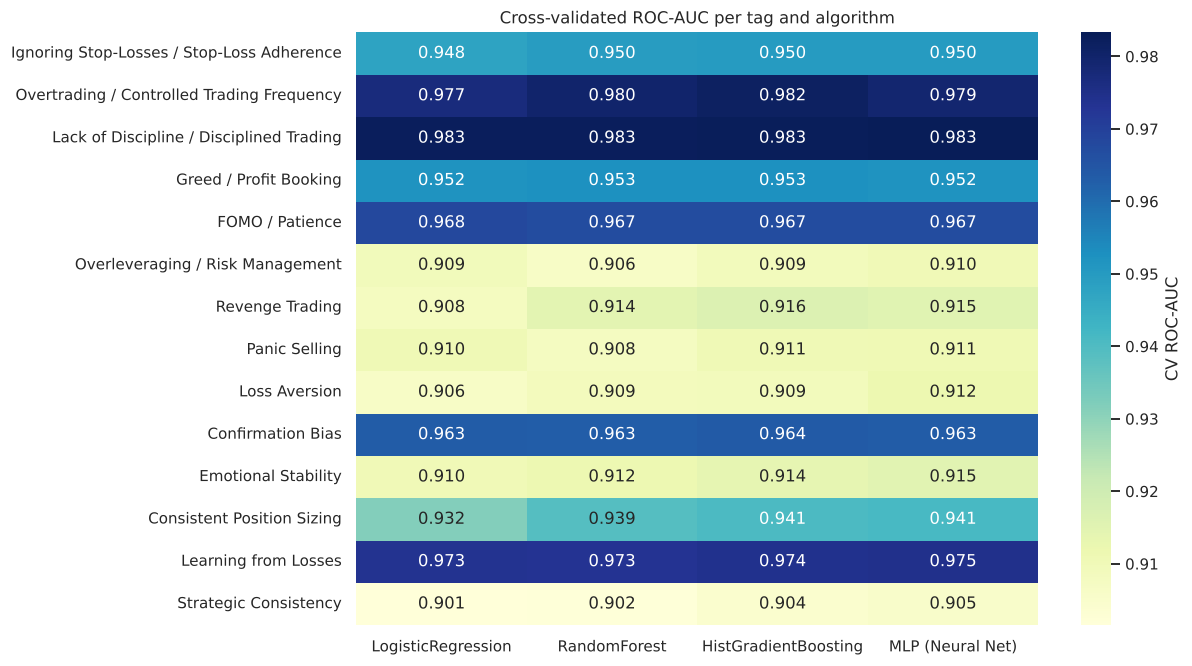

In [14]:
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(comparison.set_index("tag(s)")[algo_cols], annot=True, fmt=".3f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "CV ROC-AUC"})
ax.set_title("Cross-validated ROC-AUC per tag and algorithm"); ax.set_ylabel("")
print(comparison.best_algorithm.value_counts().to_string())

## 6–7. Hyper-parameter tuning, threshold tuning and held-out test evaluation

For the best algorithm per tag:
- `RandomizedSearchCV` (GroupKFold) tunes the hyper-parameters.
- The decision threshold is picked to maximise F1 on **out-of-fold train predictions**, never on the test set.
- The final model is evaluated once on the unseen test traders.

In [15]:
t0 = time.time()
results, art = tp.tune_and_evaluate(train, test, comparison, n_iter=10, folds=3)
print(f"\ncompleted in {(time.time()-t0)/60:.1f} min")
res = tp.results_table(results)
res

  stop_loss              HistGradientBoosting   thr=0.51 acc=0.879 f1=0.851 auc=0.953 (24s)
  frequency              HistGradientBoosting   thr=0.49 acc=0.931 f1=0.922 auc=0.985 (17s)
  discipline             MLP (Neural Net)       thr=0.47 acc=0.930 f1=0.914 auc=0.984 (17s)
  profit_exit            RandomForest           thr=0.47 acc=0.873 f1=0.859 auc=0.951 (97s)
  entry_timing           LogisticRegression     thr=0.44 acc=0.904 f1=0.895 auc=0.970 (1s)
  leverage               MLP (Neural Net)       thr=0.44 acc=0.835 f1=0.796 auc=0.916 (14s)
  revenge                HistGradientBoosting   thr=0.46 acc=0.831 f1=0.810 auc=0.920 (18s)
  panic                  MLP (Neural Net)       thr=0.40 acc=0.826 f1=0.793 auc=0.912 (17s)
  loss_aversion          MLP (Neural Net)       thr=0.39 acc=0.816 f1=0.791 auc=0.914 (21s)
  confirmation_bias      HistGradientBoosting   thr=0.43 acc=0.884 f1=0.867 auc=0.959 (17s)
  emotional_stability    MLP (Neural Net)       thr=0.43 acc=0.826 f1=0.861 auc=0

,model,tag(s),algorithm,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,brier
0,stop_loss,Ignoring Stop-Losses / Stop-Loss Adherence,HistGradientBoosting,0.51,0.8790,0.8230,0.8807,0.8509,0.9528,0.9295,0.0856
1,frequency,Overtrading / Controlled Trading Frequency,HistGradientBoosting,0.49,0.9308,0.9104,0.9336,0.9218,0.9850,0.9811,0.0481
2,discipline,Lack of Discipline / Disciplined Trading,MLP (Neural Net),0.47,0.9298,0.9053,0.9232,0.9142,0.9841,0.9784,0.0500
3,profit_exit,Greed / Profit Booking,RandomForest,0.47,0.8729,0.8310,0.8891,0.8591,0.9513,0.9402,0.0888
4,entry_timing,FOMO / Patience,LogisticRegression,0.44,0.9038,0.8779,0.9123,0.8948,0.9700,0.9662,0.0677
5,leverage,Overleveraging / Risk Management,MLP (Neural Net),0.44,0.8346,0.7591,0.8374,0.7963,0.9156,0.8720,0.1134
6,revenge,Revenge Trading,HistGradientBoosting,0.46,0.8306,0.7737,0.8503,0.8102,0.9205,0.8995,0.1142
7,panic,Panic Selling,MLP (Neural Net),0.40,0.8258,0.7390,0.8562,0.7933,0.9117,0.8754,0.1157
8,loss_aversion,Loss Aversion,MLP (Neural Net),0.39,0.8159,0.7200,0.8774,0.7909,0.9143,0.8815,0.1164
9,confirmation_bias,Confirmation Bias,HistGradientBoosting,0.43,0.8838,0.8381,0.8976,0.8668,0.9593,0.9501,0.0804


AVERAGE over 14 models:
accuracy     0.8658
precision    0.8230
recall       0.8947
f1           0.8568
roc_auc      0.9426
pr_auc       0.9318


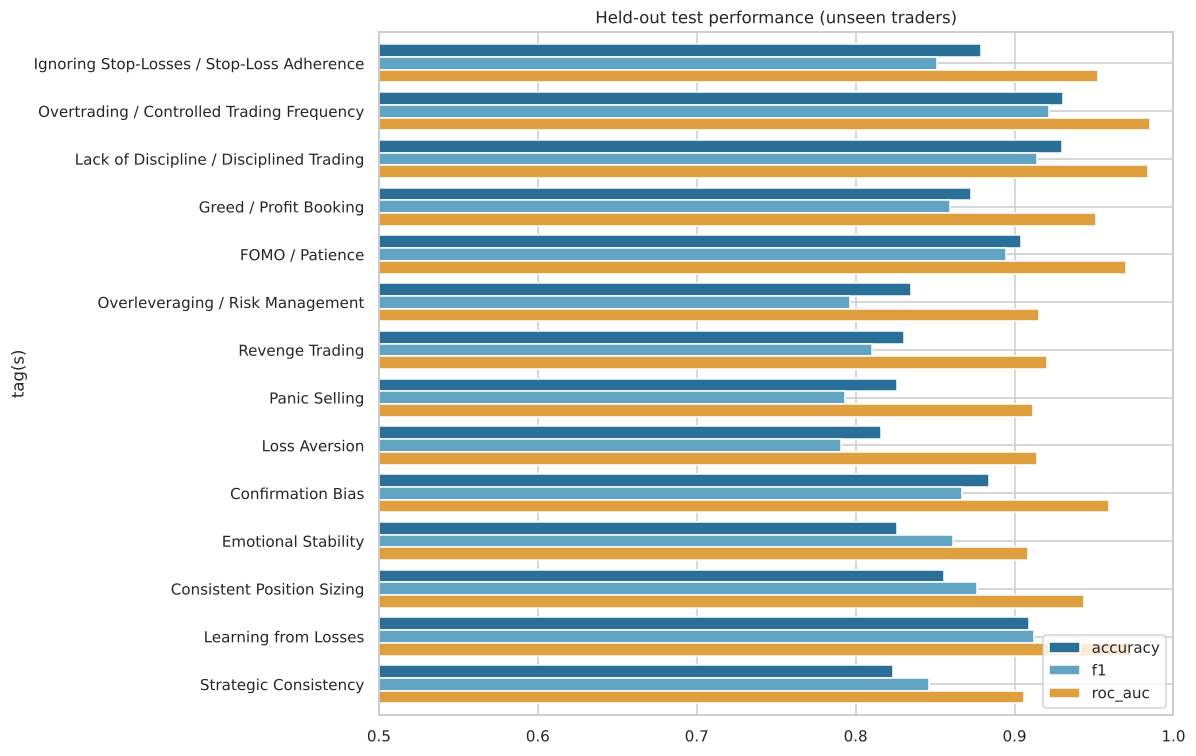

In [16]:
avg = res[["accuracy","precision","recall","f1","roc_auc","pr_auc"]].mean()
print("AVERAGE over 14 models:"); print(avg.round(4).to_string())
fig, ax = plt.subplots(figsize=(11, 7))
r = res.set_index("tag(s)")[["accuracy","f1","roc_auc"]]
r.plot.barh(ax=ax, color=["#2a6f97","#61a5c2","#e09f3e"], width=0.8); ax.invert_yaxis()
ax.set_xlim(0.5, 1); ax.set_title("Held-out test performance (unseen traders)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("reports/test_metrics.png", dpi=150)

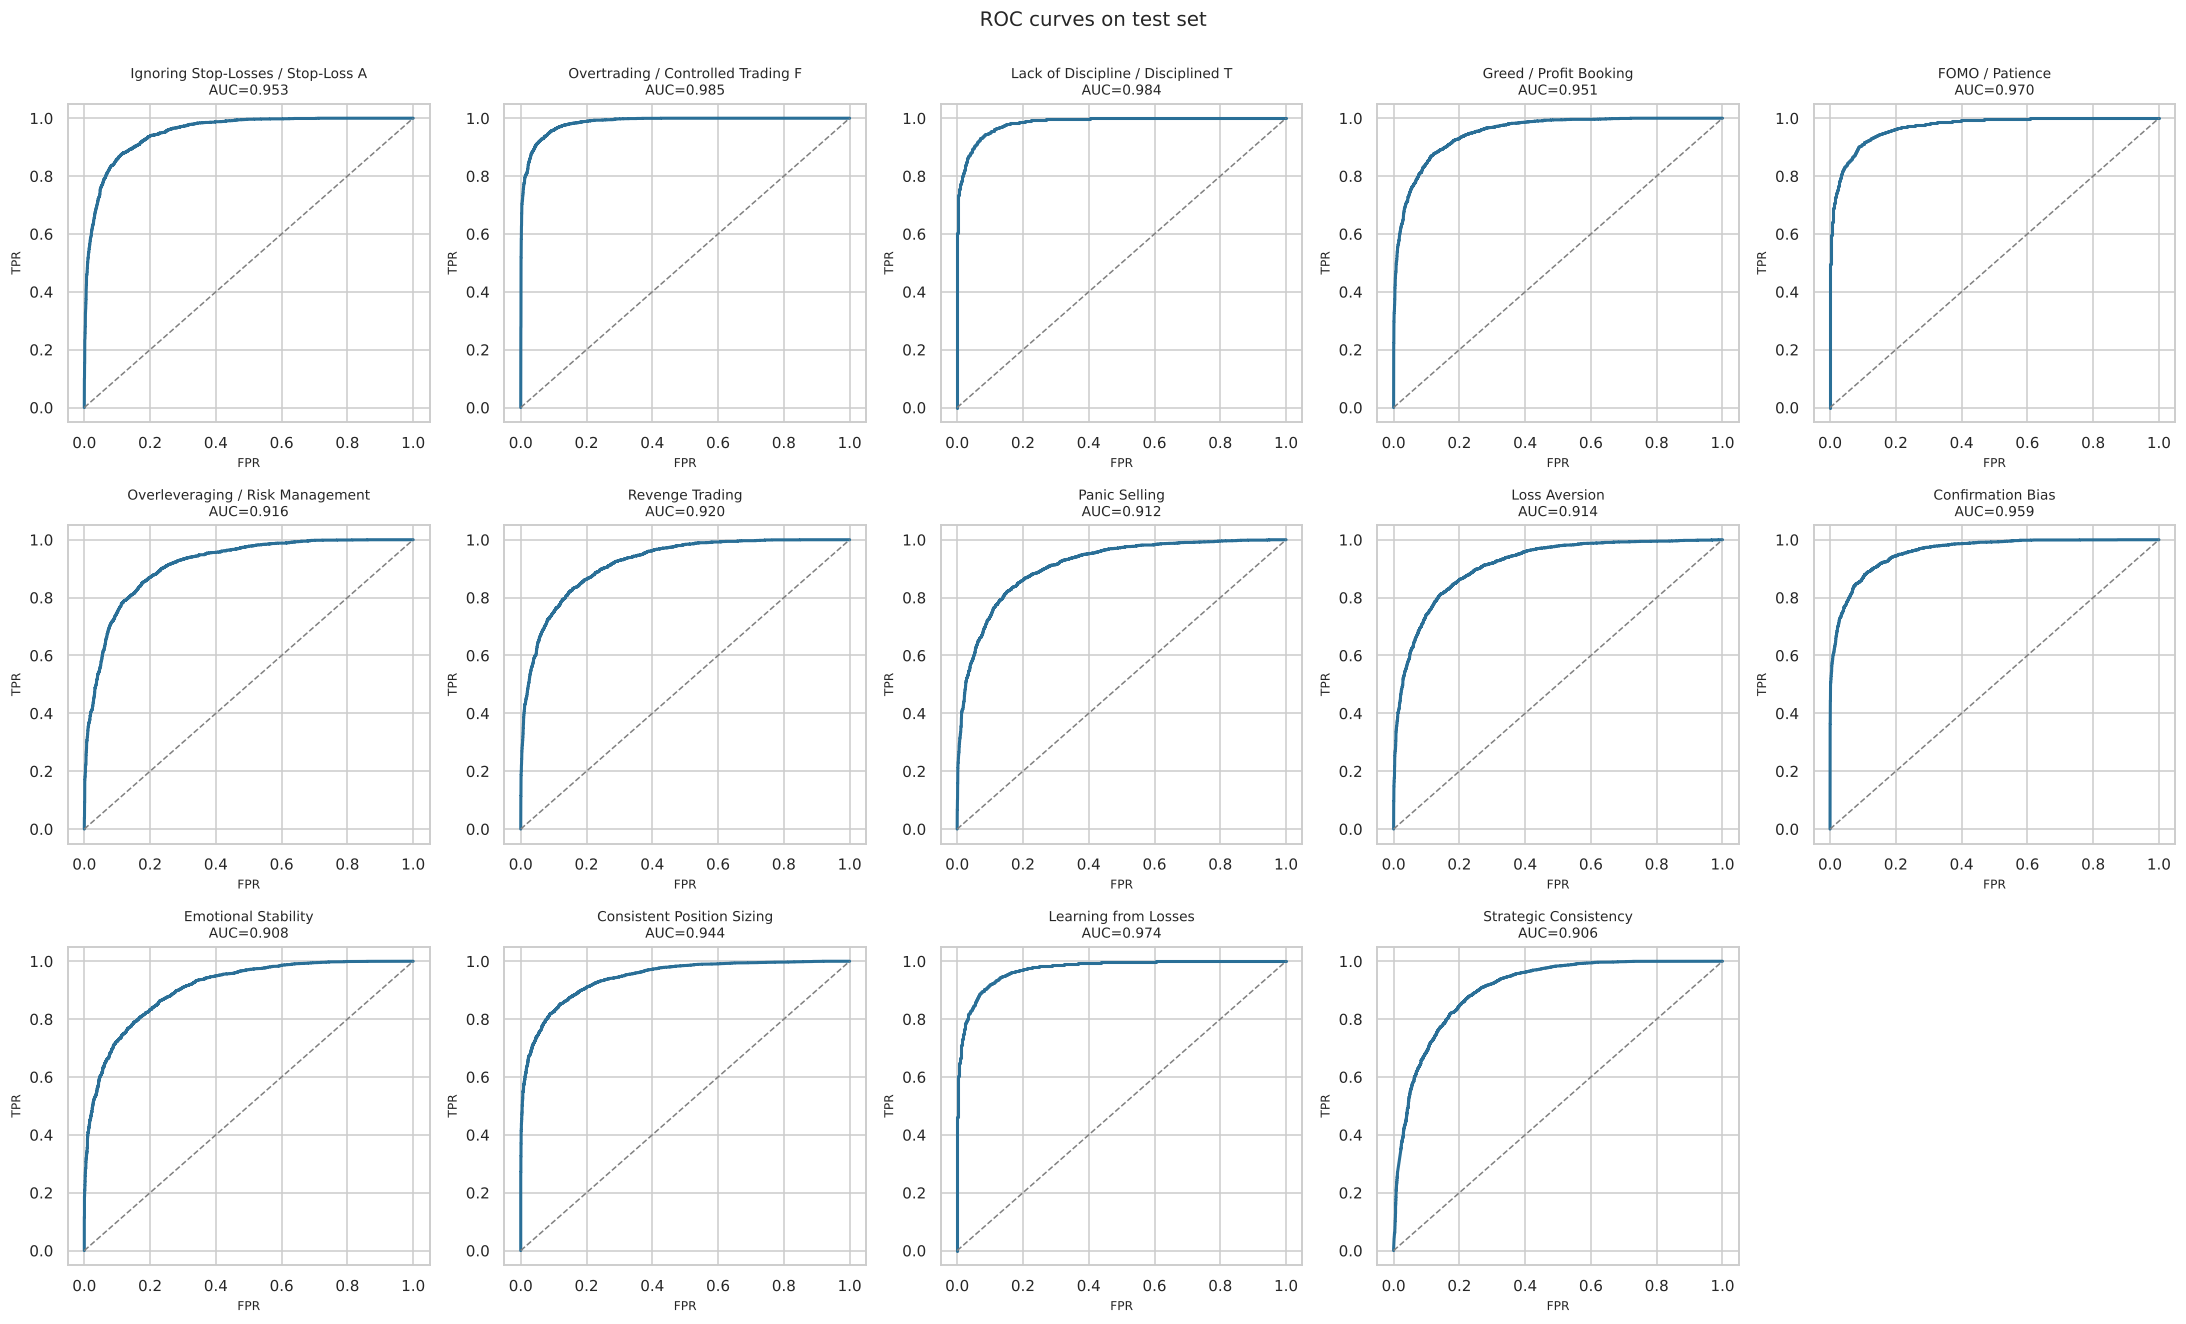

In [17]:
fig, axes = plt.subplots(3, 5, figsize=(20, 12)); axes = axes.ravel()
for ax, (name, a) in zip(axes, art.items()):
    ax.plot(a["fpr"], a["tpr"], color="#2a6f97", lw=2); ax.plot([0,1],[0,1],"--", color="grey", lw=1)
    ax.set_title(f"{results[name]['tag(s)'][:34]}\nAUC={results[name]['test']['roc_auc']:.3f}", fontsize=9)
    ax.set_xlabel("FPR", fontsize=8); ax.set_ylabel("TPR", fontsize=8)
axes[-1].axis("off"); plt.suptitle("ROC curves on test set", y=1.0); plt.tight_layout(); plt.savefig("reports/roc_curves.png", dpi=130)

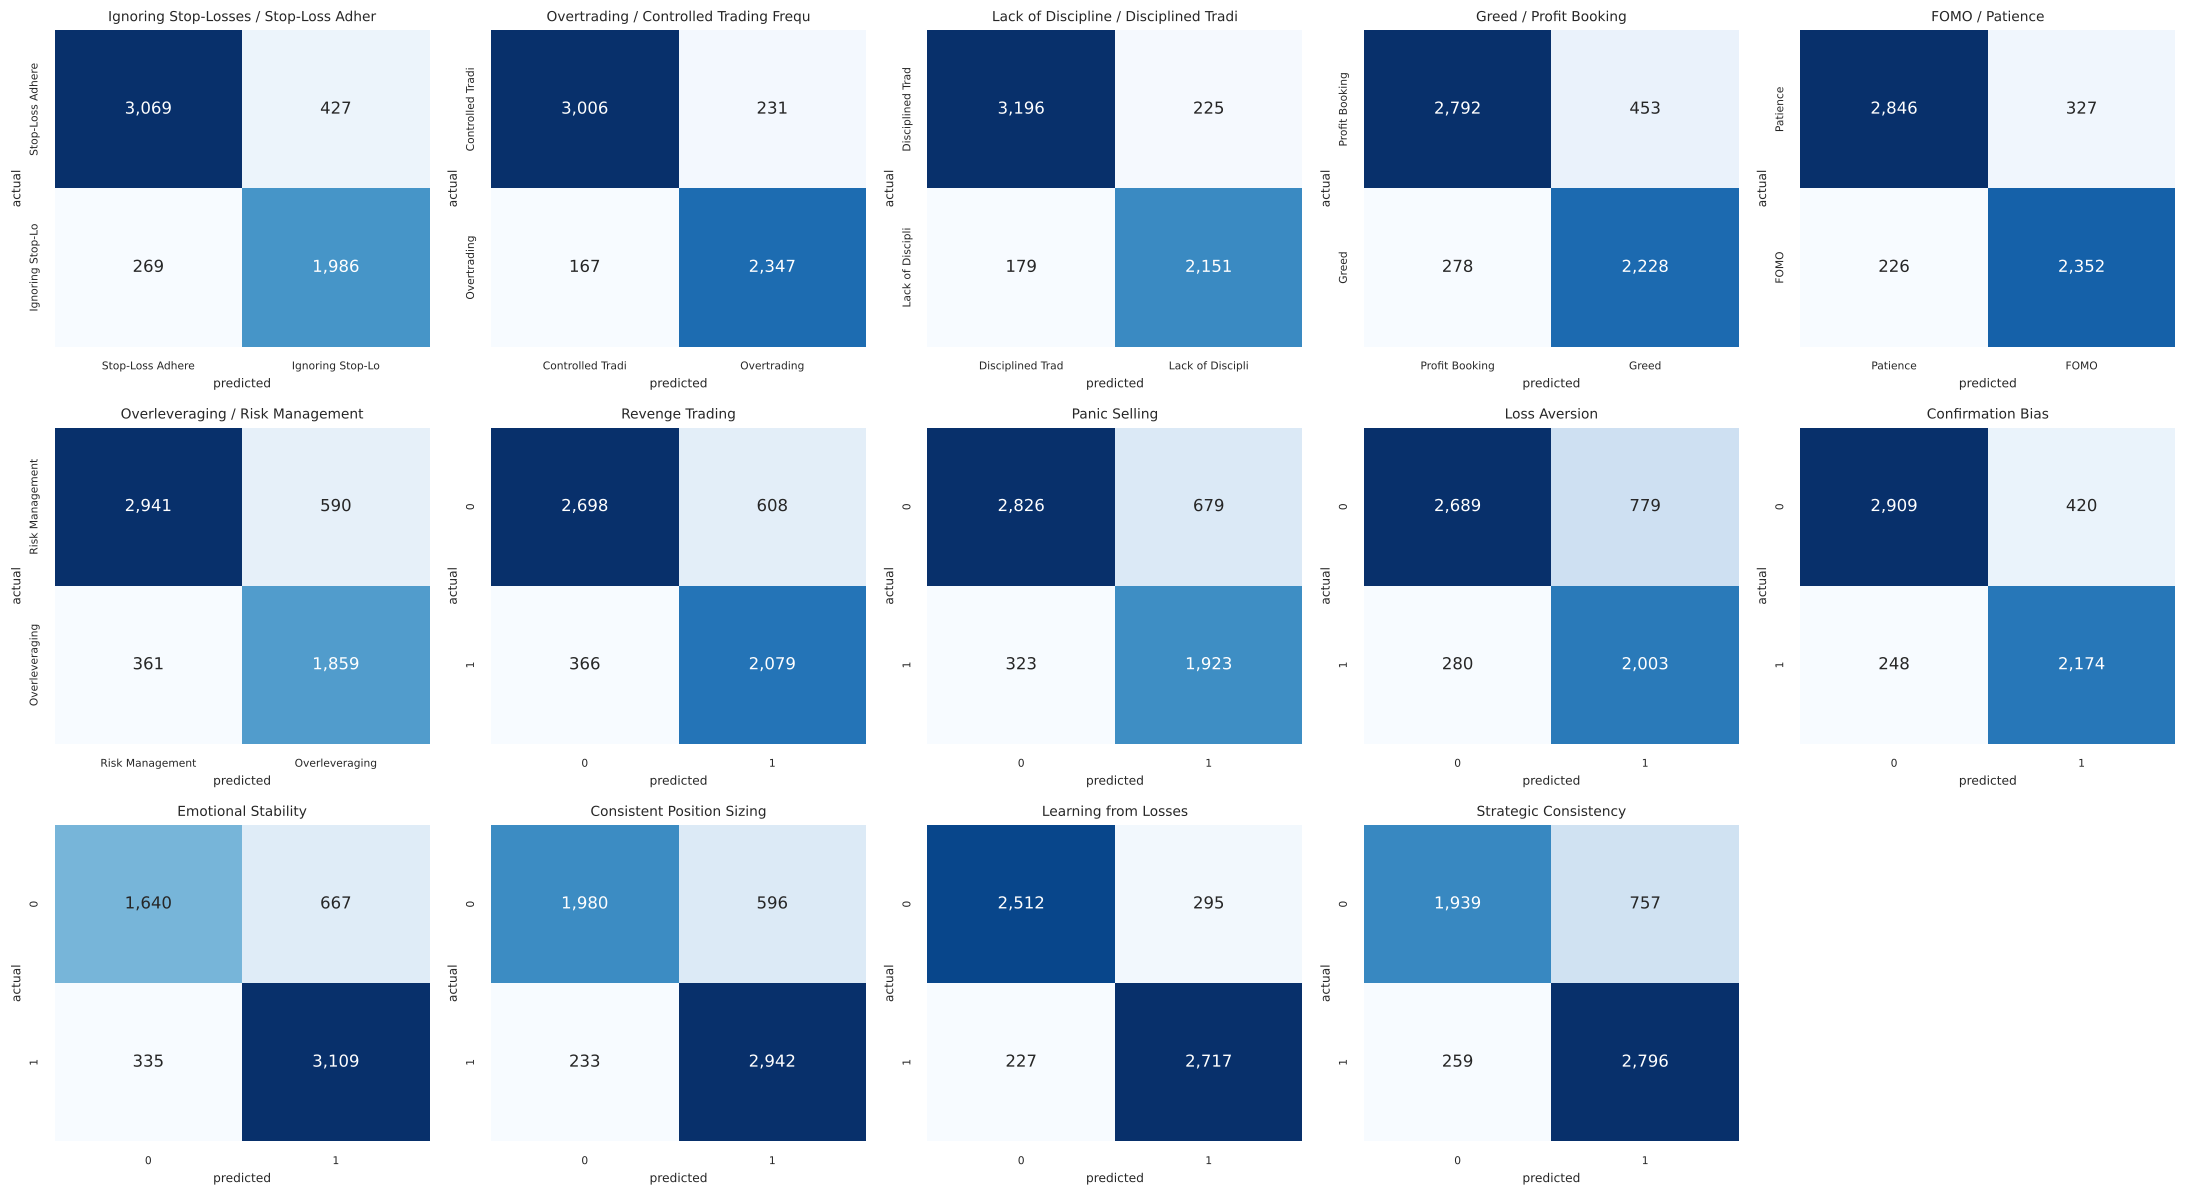

In [18]:
fig, axes = plt.subplots(3, 5, figsize=(20, 11)); axes = axes.ravel()
for ax, (name, v) in zip(axes, results.items()):
    cm = np.array(v["confusion_matrix"])
    lab = ["0", "1"] if v["type"]=="single" else [v["opposite"][:16], v["predicts"][:16]]
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax, xticklabels=lab, yticklabels=lab)
    ax.set_title(v["tag(s)"][:38], fontsize=9); ax.set_xlabel("predicted", fontsize=8); ax.set_ylabel("actual", fontsize=8)
    ax.tick_params(labelsize=7)
axes[-1].axis("off"); plt.tight_layout(); plt.savefig("reports/confusion_matrices.png", dpi=130)

## 8. Explainability: permutation feature importance

Each bar shows the drop in test ROC-AUC when that feature is shuffled. This is how the coach can say
*why* a tag was assigned (e.g. "you re-entered within 10 minutes after 40% of your losses").

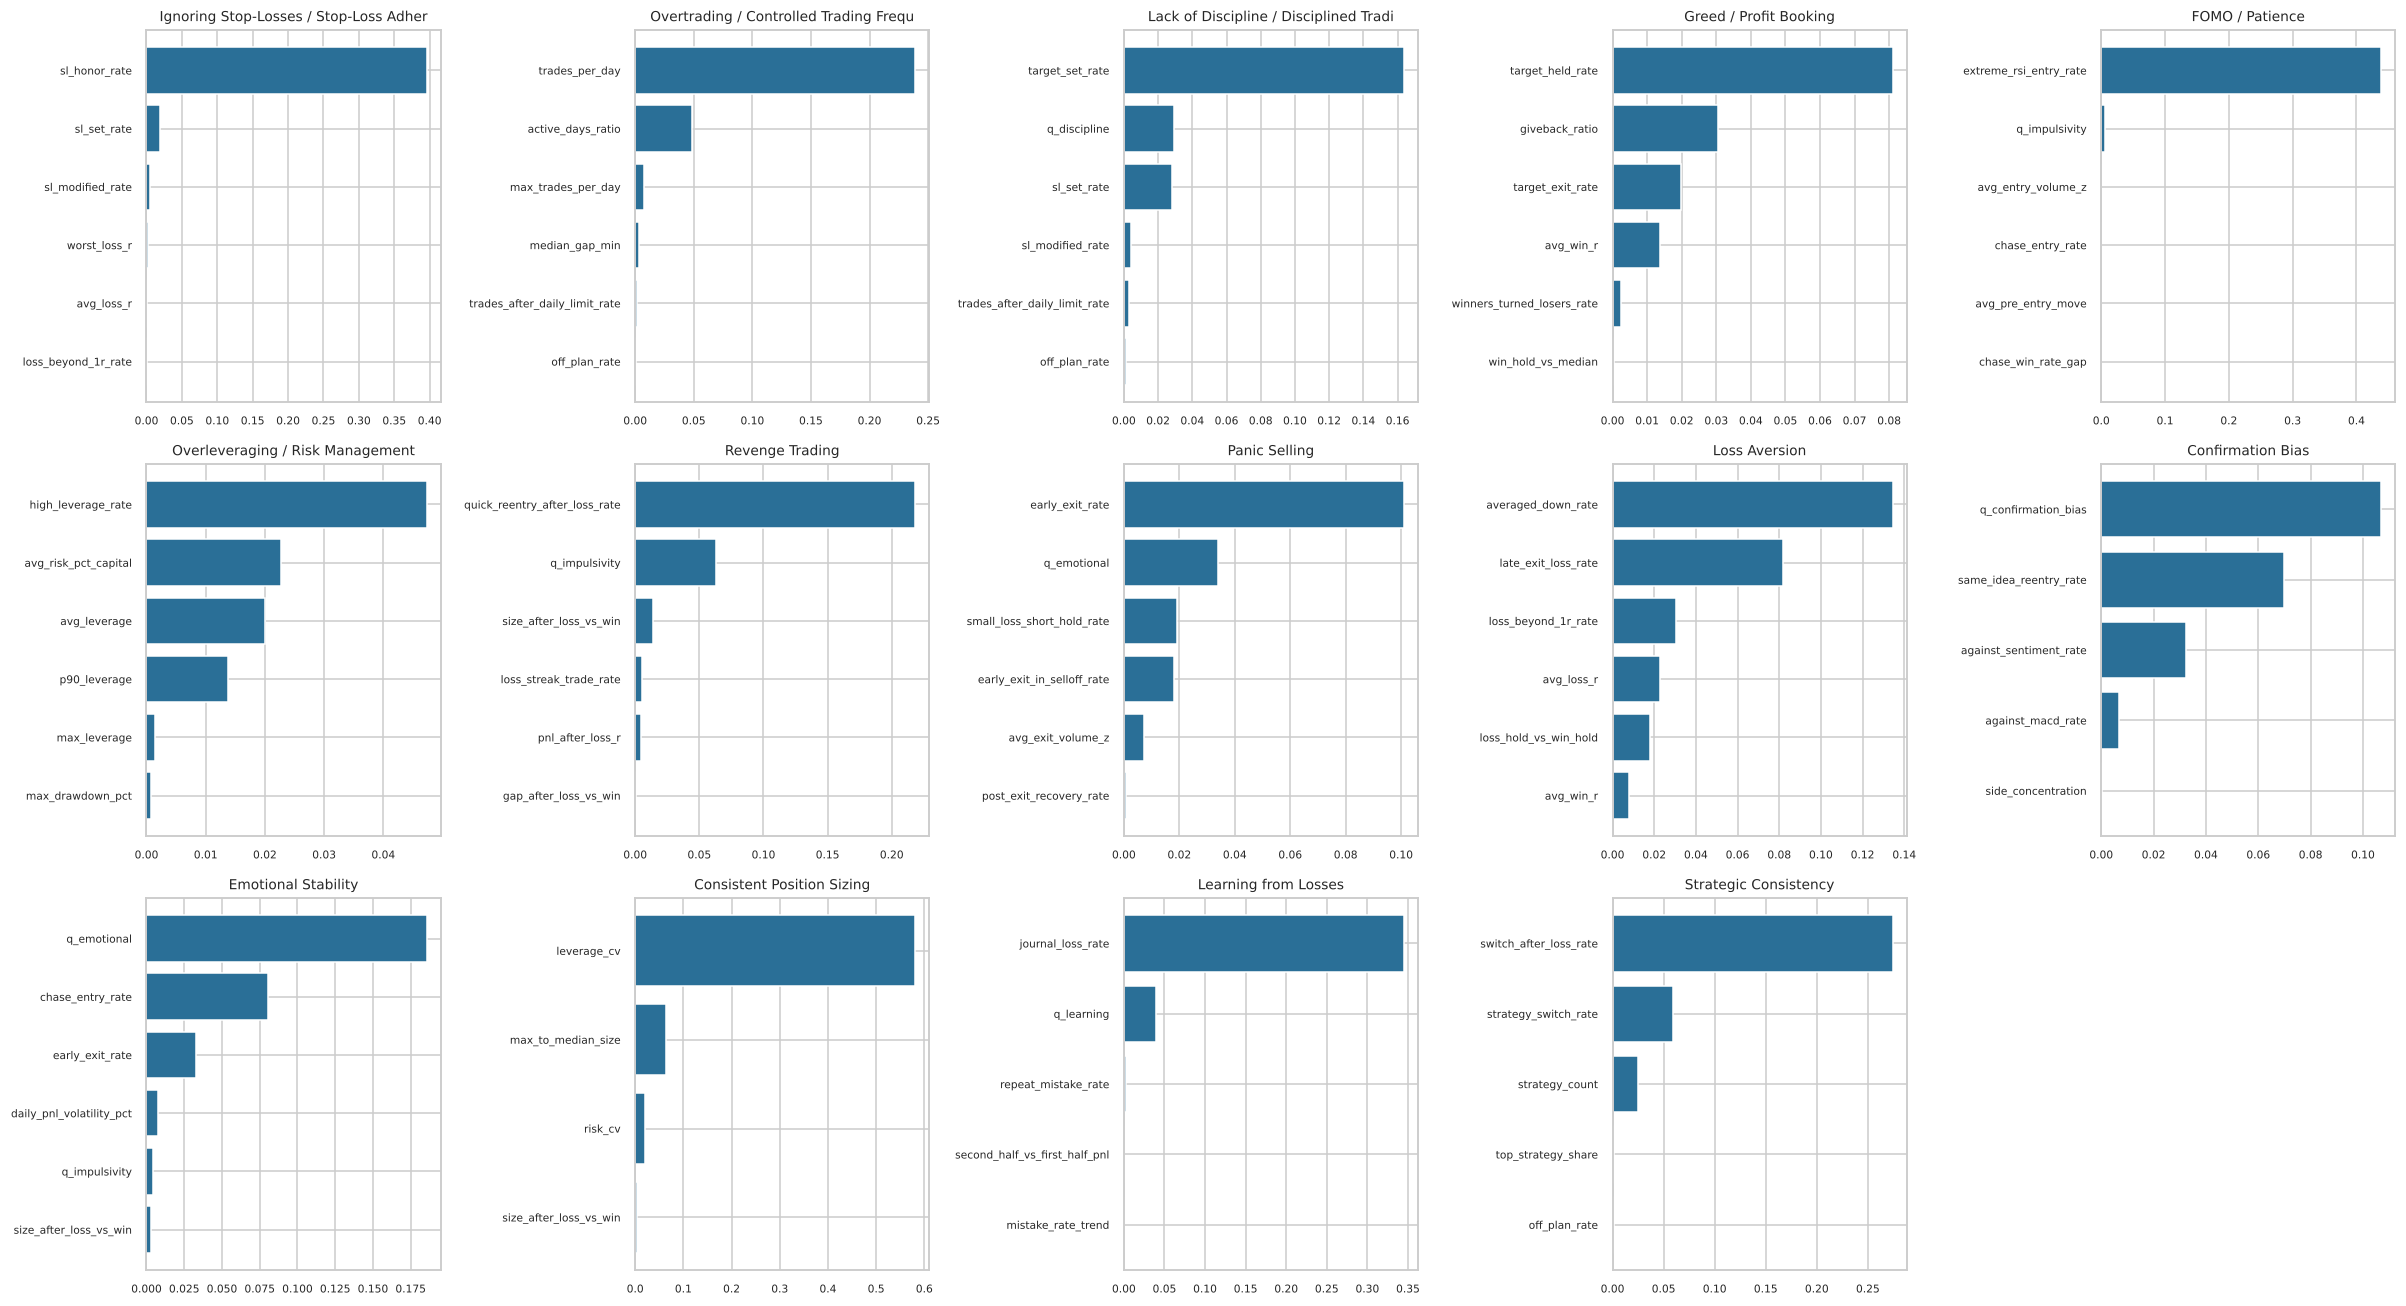

In [19]:
fig, axes = plt.subplots(3, 5, figsize=(22, 12)); axes = axes.ravel()
for ax, (name, v) in zip(axes, results.items()):
    fi = pd.DataFrame(v["feature_importance"], columns=["feature","importance"]).head(6)[::-1]
    ax.barh(fi.feature, fi.importance, color="#2a6f97"); ax.set_title(v["tag(s)"][:38], fontsize=9); ax.tick_params(labelsize=7)
axes[-1].axis("off"); plt.tight_layout(); plt.savefig("reports/feature_importance.png", dpi=130)

## 9. Does more data help? Learning curves

To check that the dataset is big enough, each model is retrained on growing subsets of training traders and
scored on the same test set. The point where the curve flattens shows that adding more data would not raise accuracy much.

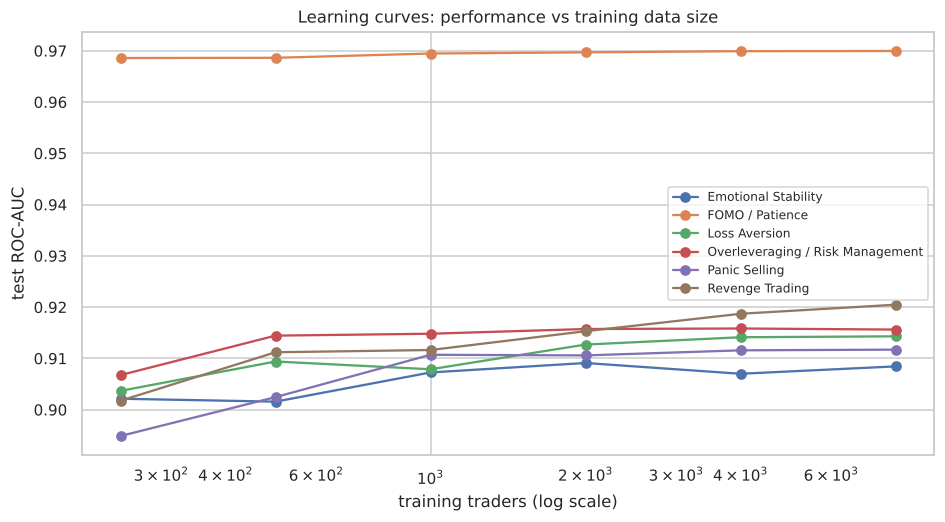

model,Emotional Stability,FOMO / Patience,Loss Aversion,Overleveraging / Risk Management,Panic Selling,Revenge Trading
traders,,,,,,
250,0.902,0.969,0.904,0.907,0.895,0.902
500,0.902,0.969,0.909,0.914,0.902,0.911
1000,0.907,0.969,0.908,0.915,0.911,0.912
2000,0.909,0.970,0.913,0.916,0.911,0.915
4000,0.907,0.970,0.914,0.916,0.912,0.919
8000,0.908,0.970,0.914,0.916,0.912,0.920


In [20]:
import joblib
from sklearn.base import clone
sizes = [250, 500, 1000, 2000, 4000, train.trader_id.nunique()]
ids = train.trader_id.drop_duplicates().sample(frac=1, random_state=0).values
curve = []
for name in ["revenge", "panic", "emotional_stability", "entry_timing", "loss_aversion", "leverage"]:
    b = joblib.load(f"models/{name}.joblib"); f, y = b["features"], tp.target_of(b["config"])
    for n in sizes:
        sub = train[train.trader_id.isin(ids[:n])]
        m = clone(b["model"]).fit(sub[f], sub[y])
        from sklearn.metrics import roc_auc_score
        curve.append({"model": results[name]["tag(s)"], "traders": n, "windows": len(sub),
                      "test_roc_auc": roc_auc_score(test[y], m.predict_proba(test[f])[:, 1])})
curve = pd.DataFrame(curve)
fig, ax = plt.subplots(figsize=(10, 5))
for k, g in curve.groupby("model"): ax.plot(g.traders, g.test_roc_auc, marker="o", label=k)
ax.set_xscale("log"); ax.set_xlabel("training traders (log scale)"); ax.set_ylabel("test ROC-AUC")
ax.set_title("Learning curves: performance vs training data size"); ax.legend(fontsize=8)
plt.savefig("reports/learning_curves.png", dpi=150, bbox_inches="tight")
curve.pivot(index="traders", columns="model", values="test_roc_auc").round(3)

## 10. Cold start: new users with only a questionnaire vs existing users with no questionnaire

The models are evaluated separately on test windows **with** and **without** questionnaire answers.
Tags like *Confirmation Bias* and *Emotional Stability* benefit most from self-report answers.

In [21]:
rows = []
for name, v in results.items():
    b = joblib.load(f"models/{name}.joblib"); f, y = b["features"], tp.target_of(b["config"])
    has_q = test.q_impulsivity.notna()
    for lbl, mask in [("with questionnaire", has_q), ("no questionnaire", ~has_q)]:
        rows.append({"tag(s)": v["tag(s)"], "subset": lbl, "uses_q_feature": any(c.startswith("q_") for c in f),
                     "roc_auc": roc_auc_score(test.loc[mask, y], b["model"].predict_proba(test.loc[mask, f])[:, 1])})
cold = pd.DataFrame(rows).pivot_table(index=["tag(s)","uses_q_feature"], columns="subset", values="roc_auc").round(3)
cold

,subset,no questionnaire,with questionnaire
tag(s),uses_q_feature,,
Confirmation Bias,True,0.937,0.967
Consistent Position Sizing,False,0.938,0.946
Emotional Stability,True,0.849,0.930
FOMO / Patience,True,0.965,0.972
Greed / Profit Booking,False,0.949,0.952
Ignoring Stop-Losses / Stop-Loss Adherence,False,0.948,0.955
Lack of Discipline / Disciplined Trading,True,0.976,0.987
Learning from Losses,True,0.965,0.977
Loss Aversion,False,0.909,0.917


## 11. Inference: full 20-tag report for unseen test traders

In [22]:
from predict import analyze, _MODELS
import predict; predict._MODELS = None   # reload freshly tuned models
hidden = pd.read_csv("data/hidden_traits.csv")
q_ids = set(quest.trader_id); test_ids = [t for t in test.trader_id.unique() if t in q_ids]
h = hidden[hidden.trader_id.isin(test_ids)].copy()
h["badness"] = h[["revenge","frequency","entry_timing","discipline","leverage","stop_loss","panic","loss_aversion","profit_exit"]].mean(1)
personas = {"impulsive": h.nlargest(5, "badness").trader_id.iloc[-1], "disciplined": h.nsmallest(5, "badness").trader_id.iloc[-1],
            "fearful": h.nlargest(3, "panic").trader_id.iloc[-1]}
import os; os.makedirs("samples", exist_ok=True)
for k, tid in personas.items():
    tr = trades[trades.trader_id == tid]; qq = quest[quest.trader_id == tid]
    last_month = tr[tr.trade_date >= sorted(tr.trade_date.unique())[-20]]
    last_month.to_csv(f"samples/persona_{k}_trades.csv", index=False); qq.to_csv(f"samples/persona_{k}_questionnaire.csv", index=False)
    r = analyze(last_month, qq)
    truth = labels.set_index("trader_id").loc[tid]
    present = [t for t in r["tags"] if t["present"]]
    correct = sum(truth[t["tag"]] == 1 for t in present)
    print(f"\n=== {k.upper()} trader {tid}: behaviour score {r['behaviour_score']}/100 | {len(last_month)} trades | "
          f"{correct}/{len(present)} detected tags match ground truth")
    for t in sorted(present, key=lambda x: -x["probability"]):
        print(f"   {'NEG' if t['polarity']=='negative' else 'POS'}  {t['tag']:30s} p={t['probability']:.2f}  truth={int(truth[t['tag']])}")


=== IMPULSIVE trader TR02697: behaviour score 7/100 | 139 trades | 8/9 detected tags match ground truth
   NEG  Lack of Discipline             p=1.00  truth=1
   NEG  FOMO                           p=1.00  truth=1
   NEG  Overtrading                    p=1.00  truth=1
   NEG  Loss Aversion                  p=1.00  truth=1
   NEG  Confirmation Bias              p=1.00  truth=1
   NEG  Ignoring Stop-Losses           p=1.00  truth=1
   NEG  Revenge Trading                p=0.99  truth=1
   NEG  Greed                          p=0.98  truth=1
   NEG  Overleveraging                 p=0.72  truth=0

=== DISCIPLINED trader TR04140: behaviour score 94/100 | 33 trades | 10/10 detected tags match ground truth
   POS  Controlled Trading Frequency   p=1.00  truth=1
   POS  Patience                       p=1.00  truth=1
   POS  Consistent Position Sizing     p=1.00  truth=1
   POS  Learning from Losses           p=1.00  truth=1
   POS  Profit Booking                 p=1.00  truth=1
   POS  Stop-Los

## Conclusion

- **Dataset:** about 1.9 million simulated trades from 10,000 traders, with trade book, order book, market context and questionnaire columns, cut into 20-trading-day training windows.
- **Models:** 14 binary models cover all 20 tags. For each tag the best of 4 algorithm families was picked by grouped cross-validation, then tuned, with a decision threshold chosen on out-of-fold predictions.
- **Results:** see the test table in section 7. The hardest tags are the most internal ones (Panic Selling, Emotional Stability), which matches how hard they are to spot from trades alone.
- **Next steps with real users:** keep the same features and pipeline, and fine-tune on labels from real users via questionnaire answers, expert review of trade journals, and coach-chat feedback.